# Iris Flower Classification
**CodeAlpha Data Science Internship: Task 1**

Goal: classify iris flowers into three species (*setosa*, *versicolor*, *virginica*) from four measurements: sepal length, sepal width, petal length and petal width.

Dataset: [Iris CSV on Kaggle](https://www.kaggle.com/datasets/saurabh00007/iriscsv) (150 rows, 50 per species).

Steps:
1. Load and inspect the data
2. Exploratory data analysis (EDA)
3. Train/test split and feature scaling
4. Train and compare several classifiers
5. Evaluate the best model on the test set
6. Save the model and predict new flowers

## 1. Import libraries and load the data

In [1]:
import os
import sys

import joblib
import matplotlib
import pandas as pd
import seaborn as sns

IN_NOTEBOOK = "ipykernel" in sys.modules
if not IN_NOTEBOOK:
    matplotlib.use("Agg")  # running as a script: save charts without opening windows
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")
os.makedirs("images", exist_ok=True)
os.makedirs("model", exist_ok=True)


def save_fig(name):
    plt.tight_layout()
    plt.savefig(f"images/{name}.png", dpi=120, bbox_inches="tight")
    if IN_NOTEBOOK:
        plt.show()
    plt.close()

In [2]:
df = pd.read_csv("data/Iris.csv")
print("Shape:", df.shape)
df.head()

Shape: (150, 6)


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB


## 2. Data cleaning
The `Id` column is just a row number, so we drop it. We also check for missing values and duplicates.

In [4]:
df = df.drop(columns="Id")
df["Species"] = df["Species"].str.replace("Iris-", "", regex=False)

print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nRows per species:")
print(df["Species"].value_counts())

Missing values per column:
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Duplicate rows: 3

Rows per species:
Species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


There are no missing values. The 3 duplicate rows are real measurements (different flowers can measure the same), so we keep them. The classes are perfectly balanced: 50 flowers each.

In [5]:
df.describe()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


## 3. Exploratory data analysis

In [6]:
FEATURES = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]

df.groupby("Species")[FEATURES].mean().round(2)

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
Species,,,,
setosa,5.01,3.42,1.46,0.24
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


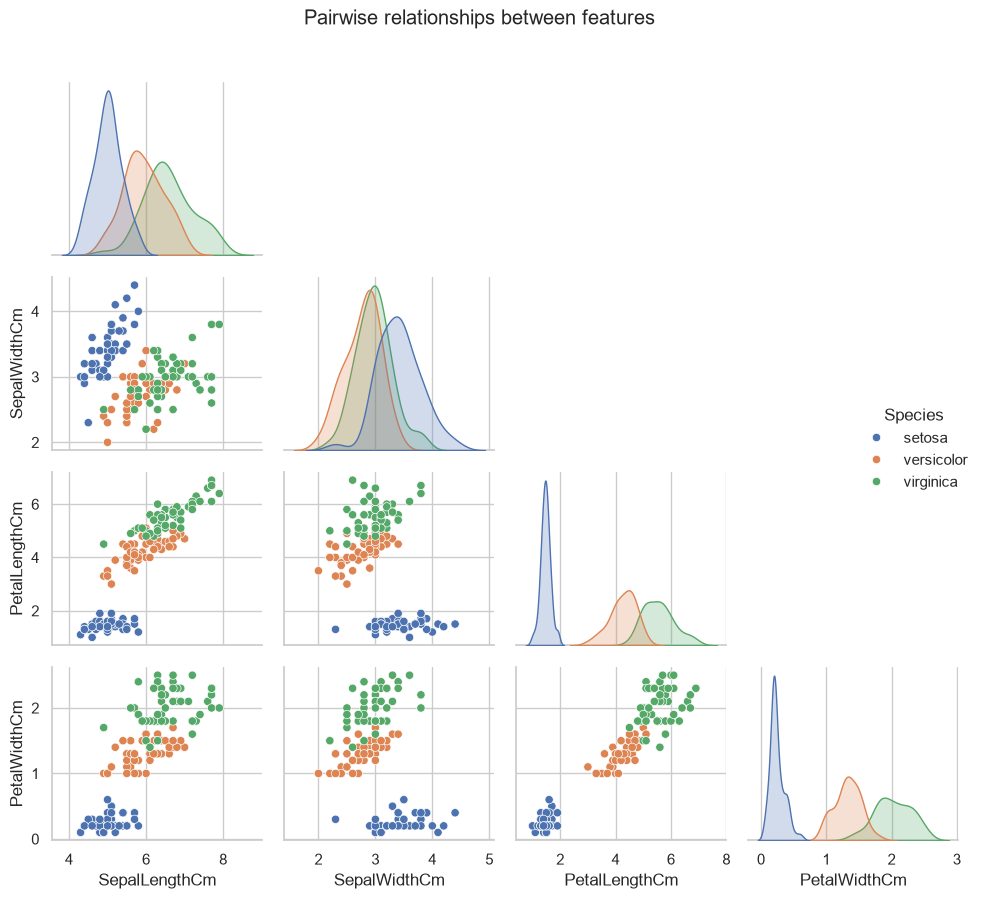

In [7]:
sns.pairplot(df, hue="Species", corner=True, height=2.2)
plt.suptitle("Pairwise relationships between features", y=1.02)
save_fig("pairplot")

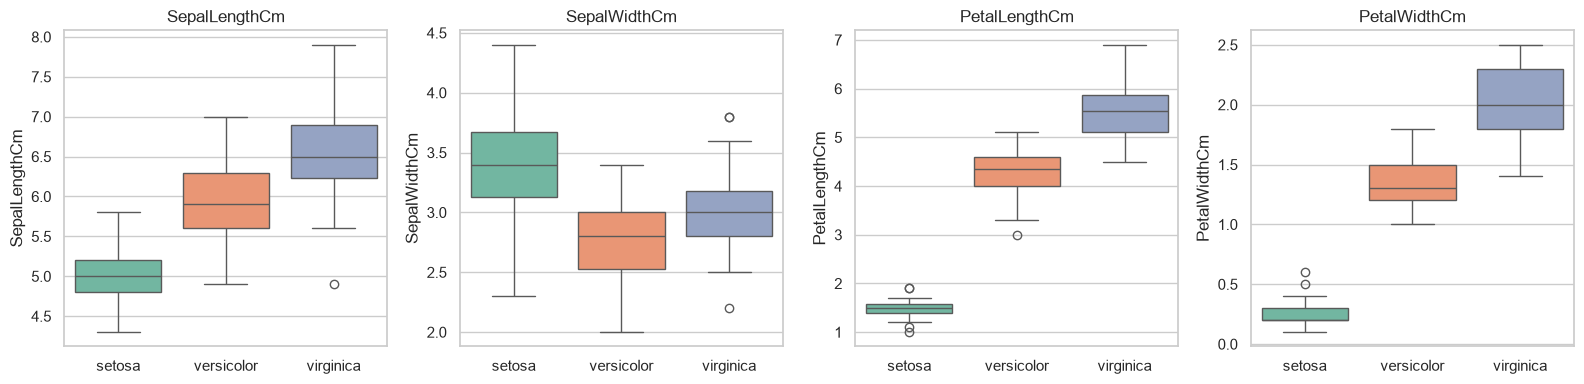

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, FEATURES):
    sns.boxplot(data=df, x="Species", y=col, hue="Species", ax=ax, palette="Set2", legend=False)
    ax.set_title(col)
    ax.set_xlabel("")
save_fig("boxplots")

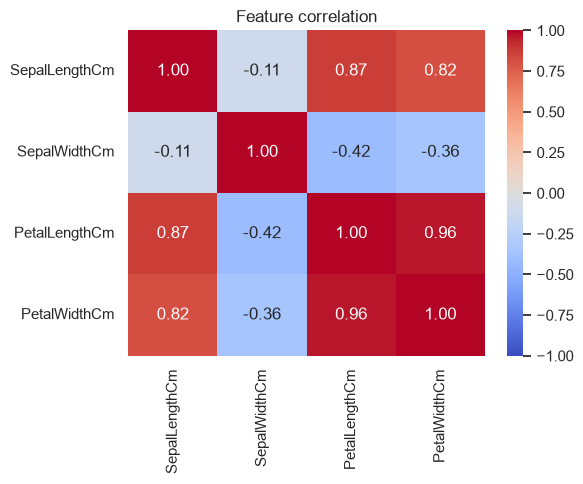

In [9]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[FEATURES].corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Feature correlation")
save_fig("correlation_heatmap")

**EDA findings**
- *Setosa* is completely separated from the other two species by petal length and petal width.
- *Versicolor* and *virginica* overlap a little, so they are where a model could make mistakes.
- Petal length and petal width are strongly correlated (0.96) and are the most informative features.
- Sepal width alone separates the species poorly.

## 4. Train/test split
We keep 20% of the data as an unseen test set. `stratify` keeps the same species ratio in both sets.

In [10]:
X = df[FEATURES]
encoder = LabelEncoder()
y = encoder.fit_transform(df["Species"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 120
Test samples: 30


## 5. Train and compare models
Each model is wrapped in a pipeline with `StandardScaler`, and compared with 5-fold cross-validation on the training set only.

In [11]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Support Vector Machine": SVC(kernel="rbf", random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []
for name, model in models.items():
    pipe = make_pipeline(StandardScaler(), model)
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")
    pipe.fit(X_train, y_train)
    test_acc = accuracy_score(y_test, pipe.predict(X_test))
    results.append({"Model": name, "CV Accuracy": scores.mean(), "CV Std": scores.std(), "Test Accuracy": test_acc})

results_df = pd.DataFrame(results).sort_values("CV Accuracy", ascending=False).reset_index(drop=True)
results_df.round(4)

,Model,CV Accuracy,CV Std,Test Accuracy
0,Support Vector Machine,0.9667,0.0167,0.9667
1,Logistic Regression,0.9583,0.0264,0.9333
2,K-Nearest Neighbors,0.9583,0.0264,0.9333
3,Decision Tree,0.9500,0.0167,0.9000
4,Random Forest,0.9500,0.0312,0.9000


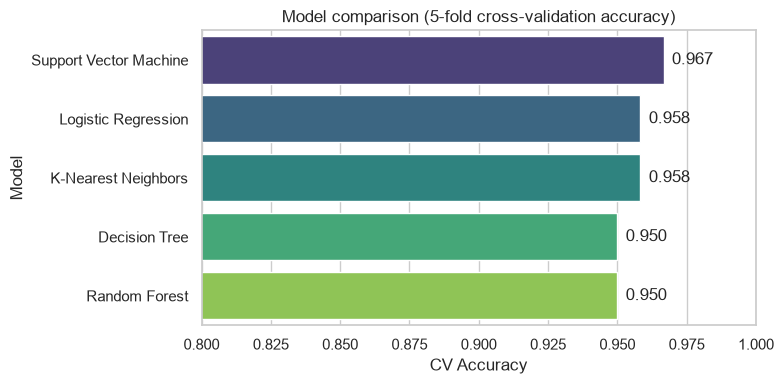

In [12]:
plt.figure(figsize=(8, 4))
sns.barplot(data=results_df, x="CV Accuracy", y="Model", hue="Model", palette="viridis", legend=False)
plt.xlim(0.8, 1.0)
plt.title("Model comparison (5-fold cross-validation accuracy)")
for i, v in enumerate(results_df["CV Accuracy"]):
    plt.text(v + 0.003, i, f"{v:.3f}", va="center")
save_fig("model_comparison")

## 6. Evaluate the best model on the test set

In [13]:
best_name = results_df.loc[0, "Model"]
best_model = make_pipeline(StandardScaler(), models[best_name])
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)

print("Best model:", best_name)
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.2%}\n")
print(classification_report(y_test, y_pred, target_names=encoder.classes_))

Best model: Support Vector Machine
Test accuracy: 96.67%

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



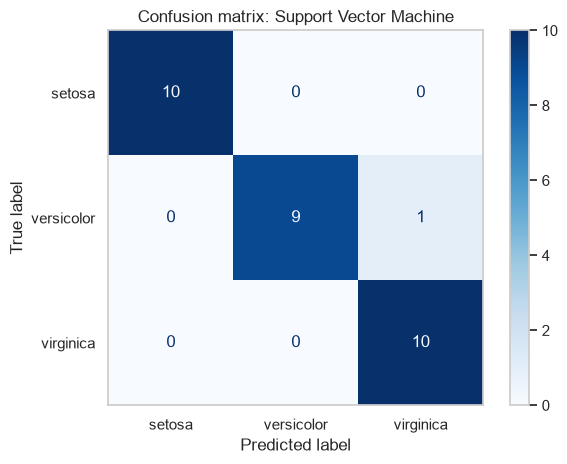

In [14]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=encoder.classes_).plot(cmap="Blues")
plt.grid(False)
plt.title(f"Confusion matrix: {best_name}")
save_fig("confusion_matrix")

### Which features matter most?
A Random Forest gives a feature importance score for each measurement.

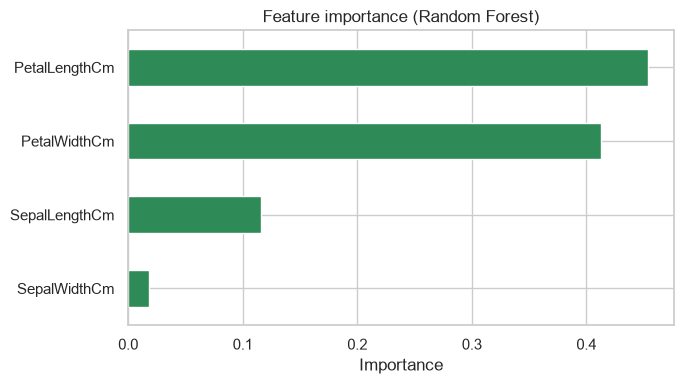

PetalLengthCm    0.454
PetalWidthCm     0.412
SepalLengthCm    0.116
SepalWidthCm     0.018
dtype: float64

In [15]:
rf = RandomForestClassifier(n_estimators=200, random_state=42).fit(X_train, y_train)
importance = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()

plt.figure(figsize=(7, 4))
importance.plot(kind="barh", color="seagreen")
plt.title("Feature importance (Random Forest)")
plt.xlabel("Importance")
save_fig("feature_importance")
importance.sort_values(ascending=False).round(3)

## 7. Save the model and predict new flowers

In [16]:
joblib.dump({"model": best_model, "encoder": encoder, "features": FEATURES}, "model/iris_model.joblib")
print("Model saved to model/iris_model.joblib")

new_flowers = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2],
     [6.0, 2.9, 4.5, 1.5],
     [6.9, 3.1, 5.8, 2.3]],
    columns=FEATURES,
)
new_flowers["Predicted Species"] = encoder.inverse_transform(best_model.predict(new_flowers))
new_flowers

Model saved to model/iris_model.joblib


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Predicted Species
0,5.1,3.5,1.4,0.2,setosa
1,6.0,2.9,4.5,1.5,versicolor
2,6.9,3.1,5.8,2.3,virginica


## 8. Conclusion
- The Iris dataset is clean and balanced, and needs very little preprocessing.
- Petal measurements are by far the strongest predictors of species.
- All five classifiers reach 95% or more cross-validation accuracy. The best model, a Support Vector Machine (RBF kernel), scores **96.7% accuracy** on the unseen test set (29 of 30 flowers correct).
- The single error is a *versicolor* predicted as *virginica*, the two species that overlap in feature space. *Setosa* is always classified correctly.

**Classification concepts covered:** features and labels, train/test split, stratification, feature scaling, cross-validation, accuracy / precision / recall / F1, and the confusion matrix.